# 02. EDA — 따릉이 '자전거 부족 발생' 패턴 탐색

**질문**: 언제, 어디서, 어떤 날씨에 자전거가 부족해지는가?

- 데이터: 서울 따릉이 대여소별 대여가능 수량(1시간 단위, 2025-10-01 ~ 12-31) + ASOS 날씨 + 대여소 정보
- 전처리: `scripts/01_preprocess.py` 결과(`data/processed/features.parquet`)
- 용어: **재고** = 그 시각 대여 가능한 자전거 수(원본의 `거치대수량` 컬럼, 해석은 가정) / **부족** = 재고 ≤ 2 / **사건(y_h1)** = 지금 재고 ≥ 3인데 1시간 뒤 재고 ≤ 2가 되는 것

> 실행 순서: 위에서부터 차례로 실행(Run All). 그림은 `reports/figures/`에 저장되어 보고서에 바로 쓸 수 있다.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

warnings.filterwarnings("ignore")

# 한글 폰트 (Windows / macOS / Linux 순서로 찾는다)
_have = {f.name for f in fm.fontManager.ttflist}
for _name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP"]:
    if _name in _have:
        plt.rcParams["font.family"] = _name
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold"})

# 색: 파랑(주), 주황(비교), 회색(보조)
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8a85"

# 경로: notebooks/ 안에서 열든, 저장소 루트에서 열든 동작
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed" / "features.parquet"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("저장소 루트:", ROOT)
print("데이터 파일 존재:", DATA.exists())

저장소 루트: /home/claude/repo
데이터 파일 존재: True


## 1. 데이터 개요와 기술통계

In [2]:
df = pd.read_parquet(DATA)
print(f"{len(df):,}행 x {df.shape[1]}열, 대여소 {df.station_id.nunique():,}개")
print("기간:", df.ts.min(), "~", df.ts.max())
print()
print(df["split"].value_counts().rename("행 수").to_frame().T)

6,081,180행 x 43열, 대여소 2,776개
기간: 2025-10-01 00:00:00 ~ 2025-12-31 23:00:00

split    train     test   gap
행 수    4681099  1391789  8292


In [3]:
num = ["stock", "temp", "rain", "humid", "wind", "snow", "docks_listed"]
desc = df[num].describe(percentiles=[.5, .9, .99]).T.round(2)
desc

,count,mean,std,min,50%,90%,99%,max
stock,6081180.0,12.87,13.55,0.0,9.0,29.0,62.0,248.0
temp,6081180.0,8.90,7.85,-11.8,8.4,19.5,24.4,27.7
rain,6081180.0,0.11,0.66,0.0,0.0,0.0,3.5,10.4
humid,6081180.0,66.09,18.15,22.0,67.0,91.0,98.0,100.0
wind,6081180.0,2.22,1.02,0.1,2.1,3.6,4.9,5.8
snow,6081180.0,0.07,0.44,0.0,0.0,0.0,1.9,5.1
docks_listed,6070411.0,12.04,5.55,2.0,10.0,20.0,31.0,62.0


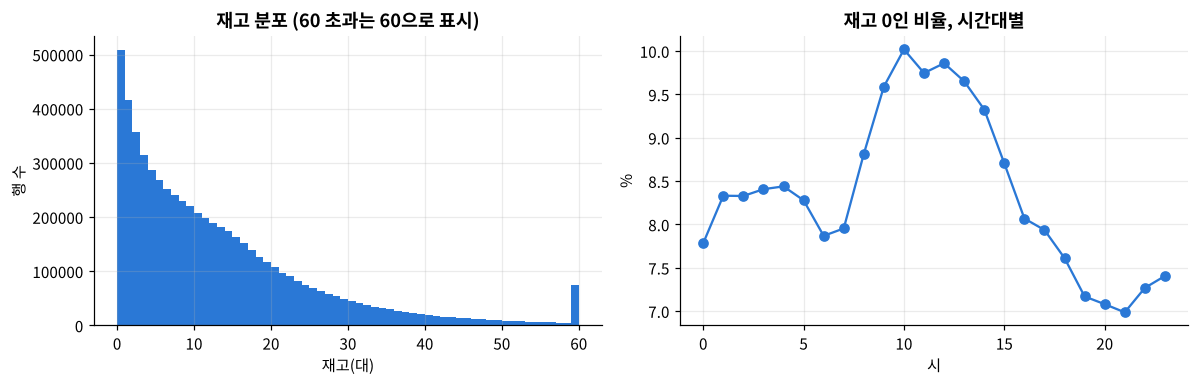

In [4]:
# 재고 분포: 대부분 작은 값, 긴 꼬리
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
df["stock"].clip(upper=60).plot.hist(bins=60, ax=ax[0], color=BLUE)
ax[0].set(title="재고 분포 (60 초과는 60으로 표시)", xlabel="재고(대)", ylabel="행 수")
(df["stock"] == 0).groupby(df["hour"]).mean().mul(100).plot(ax=ax[1], color=BLUE, marker="o")
ax[1].set(title="재고 0인 비율, 시간대별", xlabel="시", ylabel="%")
plt.tight_layout(); plt.savefig(FIG / "eda_01_stock_dist.png", bbox_inches="tight"); plt.show()

In [5]:
# 목표변수 사건 비율 (모델링 대상은 현재 재고 >= 3인 행)
risk = df[df.at_risk == 1]
rows = []
for h in (1, 2, 3):
    y = risk[f"y_h{h}"].dropna()
    rows.append({"예측 시점": f"{h}시간 뒤", "대상 행": f"{len(y):,}", "사건 수": f"{int(y.sum()):,}", "발생률": f"{y.mean():.2%}"})
pd.DataFrame(rows)

,예측 시점,대상 행,사건 수,발생률
0,1시간 뒤,"4,791,724","159,153",3.32%
1,2시간 뒤,"4,789,408","238,777",4.99%
2,3시간 뒤,"4,787,219","300,373",6.27%


## 2. 시간 패턴 — 부족은 언제 생기는가

출근·퇴근 시간에 자전거가 한쪽으로 쏠린다는 가설을 확인한다. 평일과 휴일(주말+공휴일)을 나눠 본다.

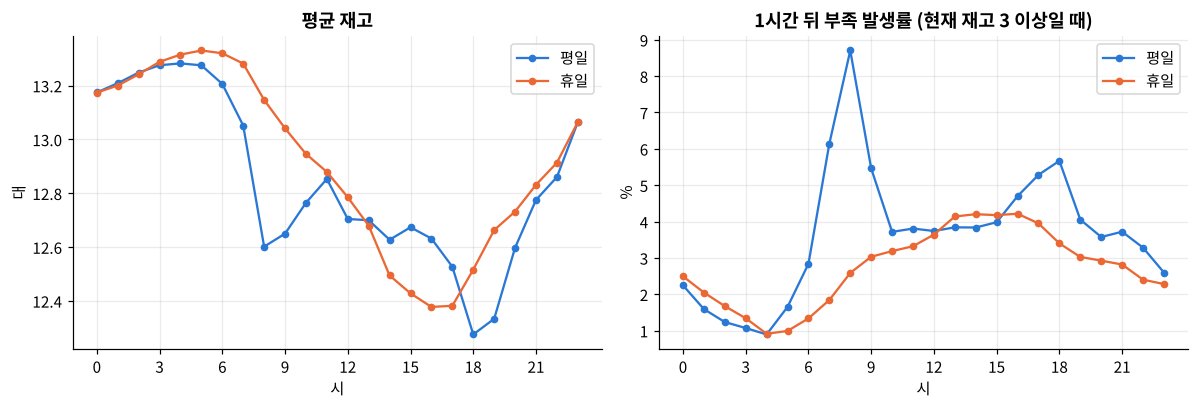

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
day_type,,,,,,,,,,,,,,,,,,,,,
평일,2.25,1.59,1.24,1.07,0.90,1.65,2.84,6.14,8.70,5.46,...,3.84,3.98,4.70,5.28,5.67,4.05,3.58,3.72,3.28,2.60
휴일,2.49,2.05,1.67,1.34,0.91,0.99,1.34,1.84,2.59,3.03,...,4.20,4.18,4.21,3.95,3.40,3.03,2.93,2.82,2.40,2.28


In [6]:
risk = df[df.at_risk == 1].copy()
risk["day_type"] = np.where(risk.is_off_day == 1, "휴일", "평일")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
m = df.assign(day_type=np.where(df.is_off_day == 1, "휴일", "평일")).groupby(["hour", "day_type"])["stock"].mean().unstack()
m.plot(ax=ax[0], color={"평일": BLUE, "휴일": ORANGE}, marker="o", ms=4)
ax[0].set(title="평균 재고", xlabel="시", ylabel="대")
r = risk.groupby(["hour", "day_type"])["y_h1"].mean().mul(100).unstack()
r.plot(ax=ax[1], color={"평일": BLUE, "휴일": ORANGE}, marker="o", ms=4)
for a in ax:
    a.legend(title="")
ax[1].set(title="1시간 뒤 부족 발생률 (현재 재고 3 이상일 때)", xlabel="시", ylabel="%")
ax[0].set_xticks(range(0, 24, 3))
plt.tight_layout(); plt.savefig(FIG / "eda_02_hourly.png", bbox_inches="tight"); plt.show()
r.round(2).T

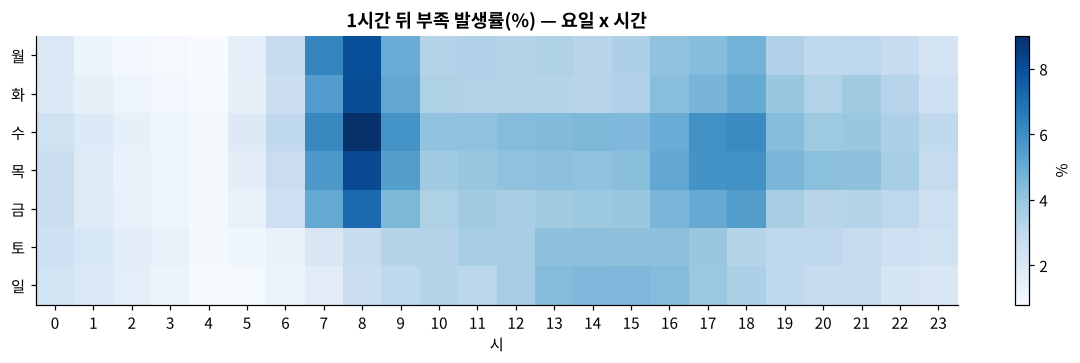

In [7]:
# 시간대 x 요일 히트맵
pv = risk.pivot_table(index="dow", columns="hour", values="y_h1", aggfunc="mean") * 100
fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(pv.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(24)); ax.set_xticklabels(range(24))
ax.set_yticks(range(7)); ax.set_yticklabels(["월", "화", "수", "목", "금", "토", "일"])
ax.grid(False)
ax.set(title="1시간 뒤 부족 발생률(%) — 요일 x 시간", xlabel="시")
fig.colorbar(im, ax=ax, label="%")
plt.tight_layout(); plt.savefig(FIG / "eda_03_heatmap_dow_hour.png", bbox_inches="tight"); plt.show()

## 3. 날씨 — 비·기온은 부족 발생과 관련이 있는가

주의: 기온은 시간대와도 얽혀 있다(낮이 따뜻하다). 그래서 시간대를 고정한 비교도 함께 본다.
또한 비·눈이 온 시간은 전체 2,208시간 중 일부뿐이라 표본이 적다.

관측 시각 수: {'비 안 옴': 2051, '비 옴': 154} / 눈 온 시각: 82


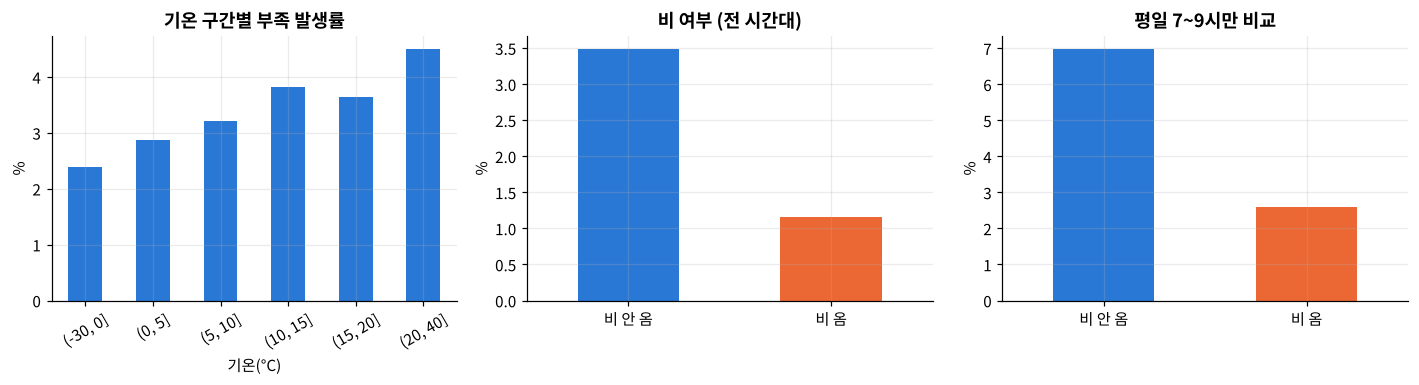

             mean    size
rain_flag                
비 안 옴      0.0698  366442
비 옴        0.0259   18156


In [8]:
risk["rain_flag"] = np.where(risk.rain > 0, "비 옴", "비 안 옴")
cnt = df.drop_duplicates("ts").assign(rain_flag=lambda d: np.where(d.rain > 0, "비 옴", "비 안 옴")).rain_flag.value_counts()
print("관측 시각 수:", cnt.to_dict(), "/ 눈 온 시각:", int((df.drop_duplicates('ts').snow > 0).sum()))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
bins = [-30, 0, 5, 10, 15, 20, 40]
tb = pd.cut(risk.temp, bins)
risk.groupby(tb)["y_h1"].mean().mul(100).plot.bar(ax=ax[0], color=BLUE)
ax[0].set(title="기온 구간별 부족 발생률", xlabel="기온(°C)", ylabel="%")
ax[0].tick_params(axis="x", rotation=30)

risk.groupby("rain_flag")["y_h1"].mean().mul(100).plot.bar(ax=ax[1], color=[BLUE, ORANGE])
ax[1].set(title="비 여부 (전 시간대)", xlabel="", ylabel="%"); ax[1].tick_params(axis="x", rotation=0)

# 같은 시간대(출근 7~9시, 평일)로 고정하고 비 여부 비교
sub = risk[(risk.hour.between(7, 9)) & (risk.is_off_day == 0)]
sub.groupby("rain_flag")["y_h1"].mean().mul(100).plot.bar(ax=ax[2], color=[BLUE, ORANGE])
ax[2].set(title="평일 7~9시만 비교", xlabel="", ylabel="%"); ax[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(FIG / "eda_04_weather.png", bbox_inches="tight"); plt.show()
print(sub.groupby("rain_flag")["y_h1"].agg(["mean", "size"]).round(4))

## 4. 대여소 차이 — 어디서 부족해지는가

대여소마다 부족 발생률 차이가 크면, 모델에서 대여소 특성(위치·평균 재고·시간대별 평균 재고)이 중요한 변수가 된다.

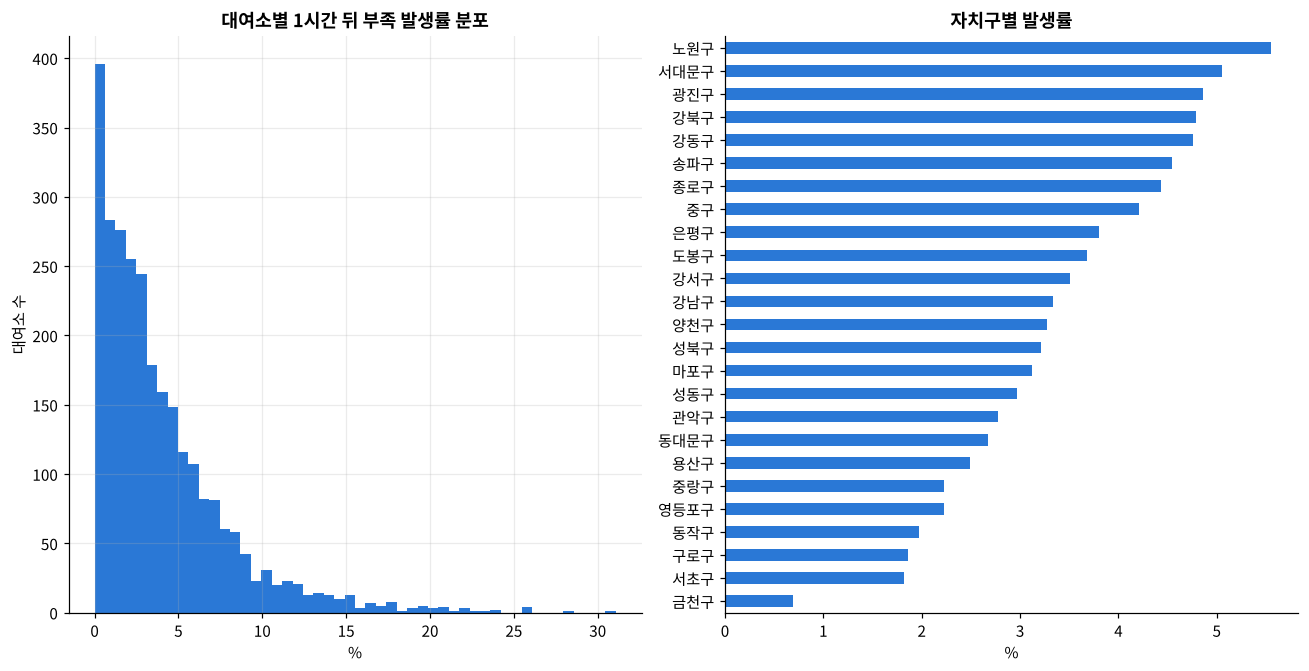

대여소 2,720개 중 발생률 상위 10%의 기준: 8.73% / 중앙값 2.88%
자치구 상위 3: 노원구 5.55%, 서대문구 5.06%, 광진구 4.86% / 하위 3: 금천구 0.69%, 서초구 1.82%, 구로구 1.86%


In [9]:
st = risk.groupby("station_id", observed=True).agg(rate=("y_h1", "mean"), n=("y_h1", "size"), mean_stock=("stock", "mean"))
st = st[st.n >= 500]
fig, ax = plt.subplots(1, 2, figsize=(12, 6.2))
(st.rate * 100).plot.hist(bins=50, ax=ax[0], color=BLUE)
ax[0].set(title="대여소별 1시간 뒤 부족 발생률 분포", xlabel="%", ylabel="대여소 수")
gu = risk.groupby("gu", observed=True)["y_h1"].mean().mul(100).sort_values()
gu.plot.barh(ax=ax[1], color=BLUE)
ax[1].grid(False)
ax[1].set(title="자치구별 발생률", xlabel="%", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "eda_05_station_gu.png", bbox_inches="tight"); plt.show()
print(f"대여소 {len(st):,}개 중 발생률 상위 10%의 기준: {st.rate.quantile(.9):.2%} / 중앙값 {st.rate.median():.2%}")
print("자치구 상위 3:", ", ".join(f"{k} {v:.2f}%" for k, v in gu.tail(3)[::-1].items()), "/ 하위 3:", ", ".join(f"{k} {v:.2f}%" for k, v in gu.head(3).items()))

In [10]:
# 상시 비어 있는 대여소 (전처리에서 모델 대상에서 제외한 곳 포함)
ch = pd.read_csv(ROOT / "data" / "processed" / "chronic_empty_stations.csv", dtype={"station_id": str})
print(f"재고 0 비율 50% 초과 대여소: {len(ch)}개, 그중 90% 초과(모델 제외): {int(ch.dropped_from_model.sum())}개")
ch.head(10)

재고 0 비율 50% 초과 대여소: 67개, 그중 90% 초과(모델 제외): 33개


,station_id,station_name,zero_share,observed_hours,dropped_from_model,gu
0,00212,212. 여의도역 1번출구 옆,1.0,2205,True,영등포구
1,00764,764. 목동청소년수련관,1.0,2205,True,양천구
2,00253,253. 신풍역 5번출구 인근,1.0,2205,True,영등포구
3,03305,3305.낙성대역 8번 출구,1.0,2205,True,관악구
4,03603,3603. 삼성역 2번출구,1.0,2205,True,강남구
5,00790,790.화곡고가 사거리,1.0,2205,True,양천구
6,01026,1026. 대명초교 입구 교차로,1.0,2205,True,강동구
7,01280,1280. 송파파크데일 2단지입구 앞 주차장,1.0,2205,True,송파구
8,01721,1721. 창동역 2번출구,1.0,392,True,NaN
9,02007,2007. 유한양행앞,1.0,2205,True,동작구


## 5. 상관관계

사건(`y_h1`)과 각 변수의 피어슨 상관계수. 이진 목표변수라 값이 작아도 순서를 보는 용도다.

상관계수 절댓값 상위: stock -0.165, lag1 -0.151, mean6 -0.139, lag2 -0.138, st_zero_share +0.128, lag3 -0.127


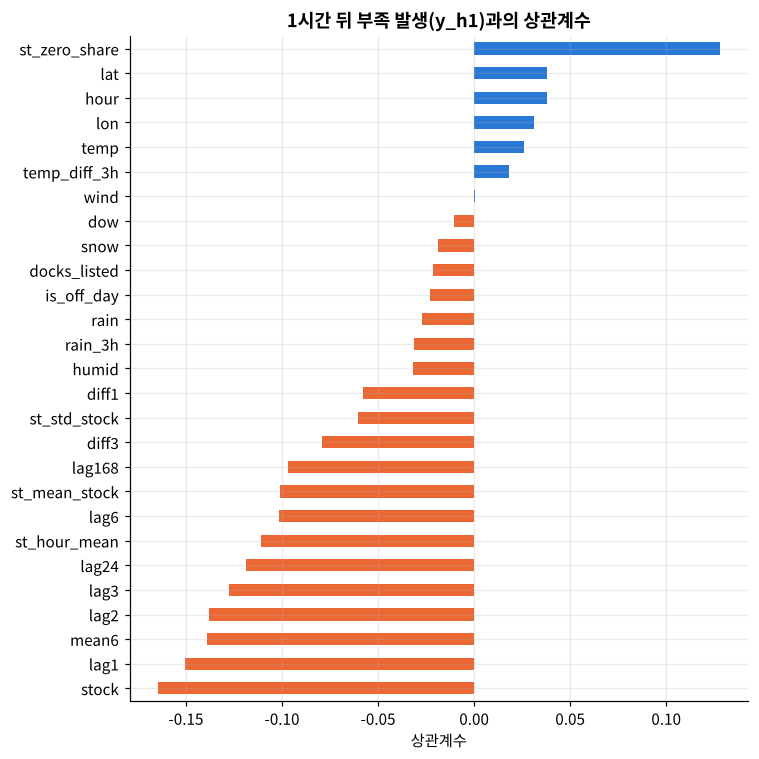

In [11]:
FEATS = ["stock", "lag1", "lag2", "lag3", "lag6", "lag24", "lag168", "diff1", "diff3", "mean6",
         "hour", "dow", "is_off_day", "temp", "rain", "rain_3h", "humid", "wind", "snow", "temp_diff_3h",
         "lat", "lon", "docks_listed", "st_mean_stock", "st_std_stock", "st_zero_share", "st_hour_mean"]
samp = risk[risk.split == "train"].sample(800_000, random_state=42)
corr = samp[FEATS + ["y_h1"]].corr()["y_h1"].drop("y_h1").sort_values()
fig, ax = plt.subplots(figsize=(7, 7))
corr.plot.barh(ax=ax, color=[ORANGE if v < 0 else BLUE for v in corr])
ax.set(title="1시간 뒤 부족 발생(y_h1)과의 상관계수", xlabel="상관계수")
print("상관계수 절댓값 상위:", ", ".join(f"{k} {v:+.3f}" for k, v in corr.reindex(corr.abs().sort_values(ascending=False).index).head(6).items()))
plt.tight_layout(); plt.savefig(FIG / "eda_06_corr_target.png", bbox_inches="tight"); plt.show()

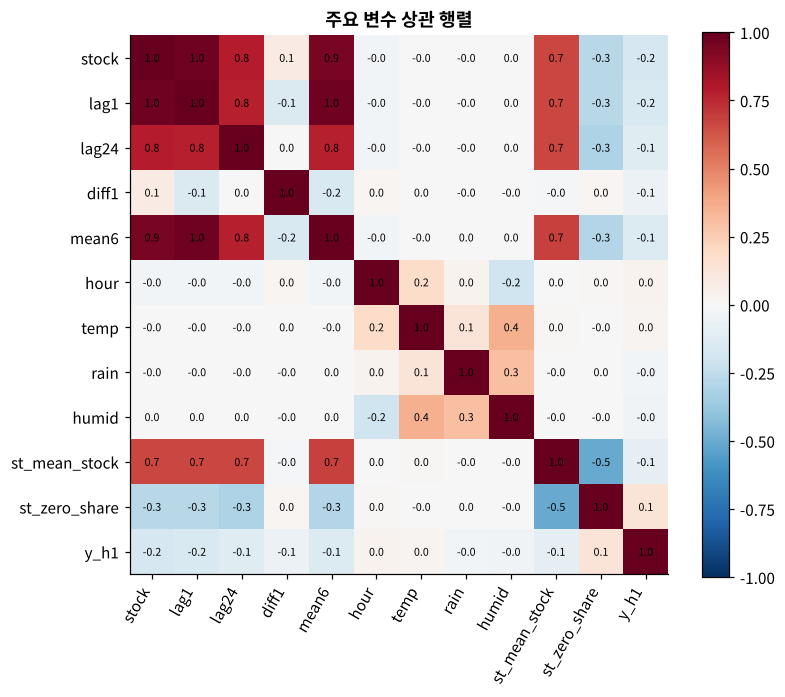

In [12]:
core = ["stock", "lag1", "lag24", "diff1", "mean6", "hour", "temp", "rain", "humid", "st_mean_stock", "st_zero_share", "y_h1"]
cm = samp[core].corr()
fig, ax = plt.subplots(figsize=(7.5, 6.3))
im = ax.imshow(cm.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.grid(False)
ax.set_xticks(range(len(core))); ax.set_xticklabels(core, rotation=60, ha="right")
ax.set_yticks(range(len(core))); ax.set_yticklabels(core)
for i in range(len(core)):
    for j in range(len(core)):
        ax.text(j, i, f"{cm.values[i, j]:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax)
ax.set_title("주요 변수 상관 행렬")
plt.tight_layout(); plt.savefig(FIG / "eda_07_corr_matrix.png", bbox_inches="tight"); plt.show()

## 6. EDA 요약

**시간**
- 평일 8시에 1시간 뒤 부족 발생률이 8.7%로 가장 높고(출근), 18시에 5.7%로 두 번째 고점(퇴근)이 있다. 휴일은 오후 3~4시에 4.2% 안팎으로 완만하다.
- 평균 재고는 시간대 변화가 작다(약 12.3~13.3대). 평균이 아니라, 특정 대여소로 자전거가 쏠리는 순간이 문제라는 뜻이다.

**날씨 (표본 주의: 비 오는 시각은 154시간뿐)**
- 기온이 높을수록 발생률이 올라간다(0°C 이하 약 2.4% → 20°C 이상 약 4.5%). 다만 기온은 시간대·계절과 겹쳐 있어 원인으로 단정할 수 없다.
- 비가 오면 발생률이 낮다(전 시간대 약 3.5% → 1.2%, 평일 7~9시 7.0% → 2.6%). 비가 오면 이용 자체가 줄어 부족도 줄어드는 것으로 보인다(해석).

**대여소**
- 대여소별 발생률 중앙값은 2.88%, 상위 10%는 8.73% 이상으로 편차가 크다. 자치구는 노원(5.55%), 서대문(5.06%), 광진(4.86%)이 높고 금천(0.69%), 서초(1.82%), 구로(1.86%)가 낮다.
- 재고 0 비율이 50%를 넘는 '상시 빈 대여소'가 67개이며, 그중 33개는 모델에서 제외했다. 이는 실행 제언(재배치·운영 점검 대상)으로 쓸 수 있다.

**상관관계**
- 단순 상관은 모두 약하다(절댓값 0.17 이하). 현재 재고(-0.165), 1시간 전 재고(-0.151), 최근 6시간 평균(-0.139)이 낮을수록, 평소 자주 비는 대여소(+0.128)일수록 위험하다.
- 선형 관계가 약하므로 비선형 모델(트리 계열)이 유리하리라는 가설을 세우고 다음 노트북에서 확인한다.

**한계**: `거치대수량`을 '대여 가능 자전거 수'로 해석한 것은 가정이다. 데이터는 2025년 4분기(한 계절)뿐이다.